## Single-column RCE model

This notebook contains the structure for your RCE model. There are key functions to complete and all visulizations are left to your design.

This RCE model will follow the Manabe and Strickler 1964 approach.

In [6]:
import numpy as np

#### Main settings and parameters

In [7]:
# Experiment selection:
# 'convective_mode_variation' runs the sweep of equilibrium modes
# 'tau0_variation' runs a sweep of surface optical thickness values (tau0)
select_experiment = 'convective_mode_variation'

# Experiment-dependent settings:
convective_mode_sweep = ["radiative", "dry", "moist"] # the three equilibrium modes to sweep over
tau0_sweep = [0.1, 1, 2, 4, 6] # surface optical depth values to sweep over

#### Parameters

In [28]:
# Physical constants
g = 9.81                  # m/s^2
Rd = 287.0                # J/(kg K)
Rv = 461.0                # J/(kg K)
cp = 1004.0               # J/(kg K)
Lv = 2.5e6                # J/kg
sigma = 5.670374419e-8    # Stefan-Boltzmann
CtoK = 273.15             # Celsius to Kelvin

# Model parameters
Nz = 60                   # number of atmospheric layers
p_surf = 100000.0         # Pa
p_top  = 5000.0           # Pa
dt = 1000.0               # time step (s)
max_iter = 50000          # maximum number of iterations
T0_init = 250.0           # initial isothermal temperature profile (K)

# Radiative transfer settings
S0 = 1361.0                     # solar constant (W/m2)
albedo = 0.3                    # planetary albedo
S_in = S0 * (1 - albedo) / 4.0  # incoming solar radiation at TOA (W/m2)
relh0 = 0.8                     # assumed constant relative humidity for moist convective mixing
tau0 = 4.0                      # optical thickness at surface (tau(p_surf) = tau0)
tau_n = 2.0                     # exponent for tau(p) = tau0 * (p/p0)^n
mu_bar = 0.6                    # diffusivity factor for conversion from I to F
max_sweeps = 10

#### Helper functions

##### Create vertical grid

In [29]:
'''
This function sets up the vertical grid and initial T-profile for the RCE model.

Its structure is as follows:

             TOP
        -------------------  p_edges[Nz] = p_top
             p_mid[Nz-1]     layer Nz-1
        -------------------  p_edges[Nz-1]
               ...
        -------------------  p_edges[2]
             p_mid[1]        layer 1
        -------------------  p_edges[1]
             p_mid[0]        layer 0
        -------------------  p_edges[0] = p_surf
            SURFACE

Index increases upward; pressure decreases upward.
Grid spacing is uniform in pressure.

Temperature is defined at layer midpoints.
Optical depth tau is defined at edges and decreases upward
(assuming tau0 > 0 and tau_n > 0).

For each layer k:
  p_mid[k] = 0.5 * (p_edges[k] + p_edges[k+1])
  dp[k]    = p_edges[k] - p_edges[k+1] > 0
  dtau[k]  = tau_edges[k] - tau_edges[k+1] > 0

'''
def get_grid_tau(Nz, p_surf, p_top, tau0, tau_n, T0_init):

    # Vertical grid (pressure edges and midpoints)
    p_edges = np.linspace(p_surf, p_top, Nz+1)    # edges (Pa), bottom --> top
    p_mid = 0.5*(p_edges[:-1] + p_edges[1:])      # pressure at layer mid-points
    dp = p_edges[:-1] - p_edges[1:]               # dp of each layer (positive)

    # Optical depth at layer edges
    tau_edges = tau0 * (p_edges / p_surf)**tau_n
    dtau = tau_edges[:-1] - tau_edges[1:]

    # Initial isothermal temperature profile (defined at layer midpoints)
    T_init = np.repeat(T0_init, Nz) # K

    grid = {}
    grid['p_edges'] = p_edges
    grid['p_mid'] = p_mid
    grid['dp'] = dp
    grid['tau_edges'] = tau_edges
    grid['dtau'] = dtau
    grid['T_init'] = T_init

    return grid

### Understanding the grid
As an initial assessment, I believe it is a good idea to create some plots to really visualize and understand the grid that will be used during our model implementation:

In [30]:
grid = get_grid_tau(Nz, p_surf, p_top, tau0, tau_n, T0_init)

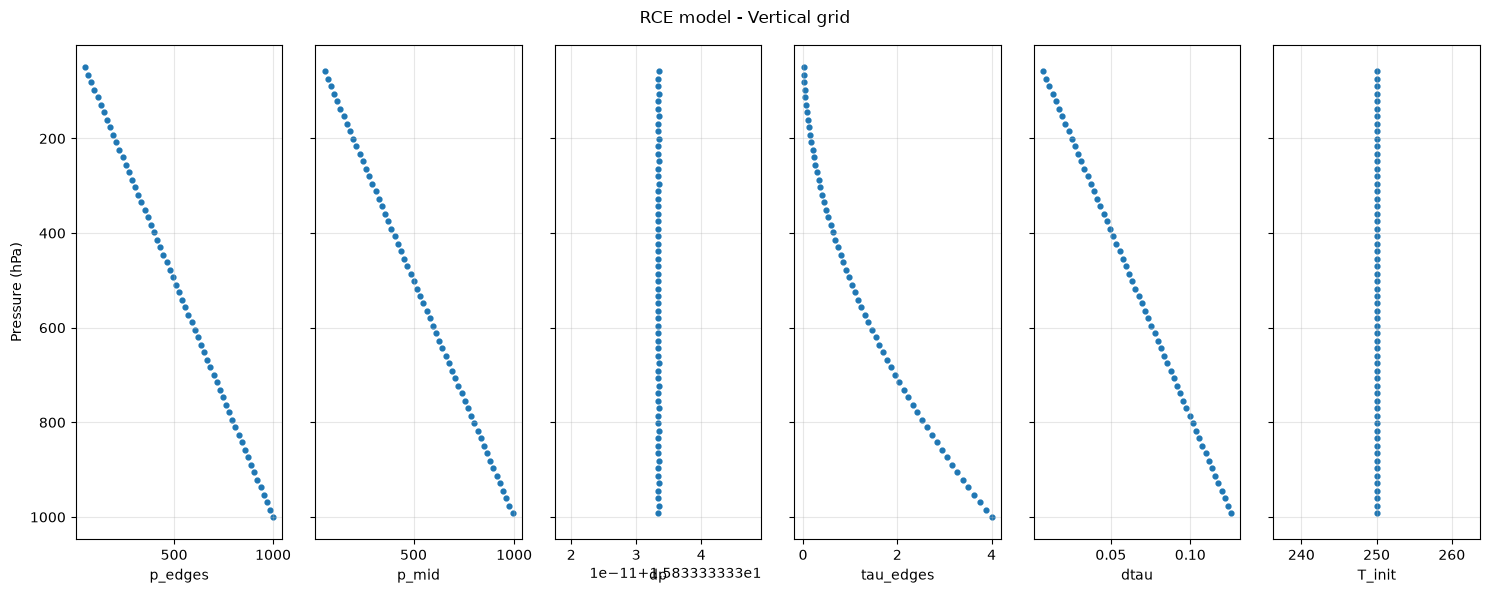

In [31]:

import matplotlib.pyplot as plt

variables = [
    "p_edges", "p_mid", "dp",
    "tau_edges", "dtau", "T_init"
]

fig, axs = plt.subplots(1, 6, figsize=(15, 6), sharey=True)

for ax, var in zip(axs, variables):

    # Pressure coordinates corresponding to each variable
    if var in ["p_edges", "tau_edges"]:
        p = grid["p_edges"] / 100
    else:
        p = grid["p_mid"] / 100

    # Convert pressure variables from Pa to hPa
    x = grid[var] / 100 if var in ["p_edges", "p_mid", "dp"] else grid[var]

    ax.scatter(x, p, s=12)
    ax.set_xlabel(var)
    ax.grid(alpha=0.3)

axs[0].set_ylabel("Pressure (hPa)")
axs[0].invert_yaxis()

fig.suptitle("RCE model - Vertical grid")
plt.tight_layout()
plt.show()


##### Thermodynamic functions

In [33]:
# saturation vapor pressure (Magnus)
def es_sat(Tk):
    """
    Tk expressed in K
    """
    Tc = Tk - 273.15
    return 610.94 * np.exp(17.625 * Tc / (Tc + 243.04))

# saturation mixing ratio from saturation vapor pressure
def qsat(Tk, p):
    eps = Rd / Rv
    e_s = es_sat(Tk)
    return eps * e_s / (p - (1-eps)*e_s)

def MALR_K_per_m(DALR, Tk, p, RH=1.0):
    """
    Moist-adiabatic lapse rate with saturation mixing ratio scaled by a given RH.
    DALR input is the dry adiabatic lapse rate, provided either in K/m or K/Pa,
    which determines the units of the returned lapse rate.
    """
    q = qsat(Tk, p) * RH
    numerator = DALR * (1.0 + (Lv * q) / (Rd * Tk))
    denominator = 1.0 + (Lv**2 * q) / (cp * Rv * Tk**2)
    return numerator / denominator

### Radiative tranfer

#### Equations to consider
We are going to use the following upwelling and downwelling expressions:
$$F^{\uparrow}_{k+1}=F^{\uparrow}_{k}Tr_k+\epsilon_kB(T_k)$$
$$F^{\downarrow}_{k}=F^{\downarrow}_{k+1}Tr_k+\epsilon_kB(T_k)$$
On top of these equations, we will also need to implement some initial conditions for the bottom and top of the grid:
- On top of the model: $F^{\downarrow}_{TOA}=0$ (where we are considering LW)
- On the surface: $F^{\uparrow}_{LW}=F^{\downarrow}_{LW}+F^{\downarrow}_{SW}$

And we can express that $F^{\downarrow}_{SW}=S_{in}$, which is the incoming solar radiation at TOA but, since shortwave is considered as transparent to our current atmosphere, it is also the incoming SW radiation at the surface.

#### Transmissivity
We will use the optical depth grid to produce the transmissivity expression:
$$Tr_k=exp\left(-D\Delta\tau_k\right)$$
Also, we will use the fact that:
$$\epsilon_k=1-Tr_k$$

#### Black body emission
Also, for each temperature layer, we will consider:
$$B(T_k)=\sigma\cdot T_k^4$$

In [34]:
# Initial conditions for downwelling flux:
F_LW_T = 0 # Downwelling LW flux at TOA

# Needed grid components:
D=1/mu_bar
    # Definition of the necessary new grid parameters:
Tr = np.exp(-D*grid["dtau"])
epsi = 1 - Tr
B_T = sigma * grid["T_init"]**4 # For the fi

# We are going to start with the downwelling. 
p_edges = np.linspace(p_surf, p_top, Nz+1)
len_F = len(p_edges) # length of 61, so from 60 t0 0 in index notation
# Definition of arrays
F_down = np.zeros(len_F)
F_up = np.zeros(len_F)

N = 59 # We will move from top to bottom
F_down[-1]=F_LW_T # Initial condition
while N >= 0:
    F_down[N] = F_down[N+1]*Tr[N] + epsi[N]*B_T[N]
    N -= 1
#print(F_down)

In [35]:
# Initial conditions for upwelling 
F_LW_S = F_down[0] + S_in # Upwelling LW flux at surface
F_up[0] = F_LW_S
N = 0
while N <= 59:
    F_up[N+1] = F_up[N]*Tr[N] + epsi[N]*B_T[N]
    N += 1

#print(F_up, p_edges)

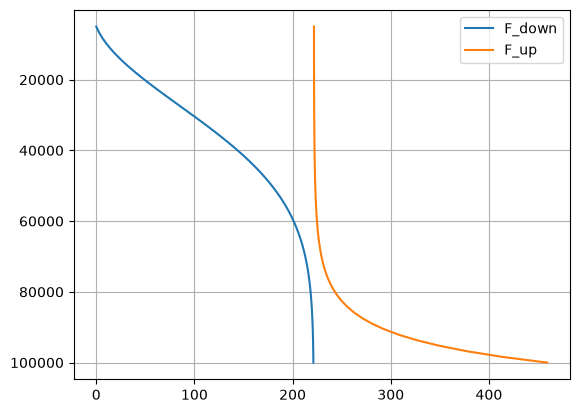

In [36]:
# Plot with initial arrays:
import matplotlib.pyplot as plt
plt.figure()
plt.plot(F_down, p_edges, label="F_down")
plt.plot(F_up, p_edges, label="F_up")
plt.gca().invert_yaxis()
plt.grid()
plt.legend()
plt.show()

Once computed the fluxes considering an Isotherm atmosphere, let us now consider the radiative heating (the temperature time evolution within a layer). Following the class notes and directly applying the hydrostatic assumption to work with p coordinates:
$$F_{net,k} = F^{up}_k-F^{down}_k$$
$$\left(\frac{dT}{dt}\right)=\frac{g}{c_p}\frac{dF_{net}}{dp}$$
Which, translated into our model's notation becomes:
$$\left(\frac{dT}{dt}\right)_k=\frac{g}{c_p}\frac{dF_{net,k}}{dp_k}=\frac{g}{c_p}\frac{F_{net,k}-F_{net,k+1}}{p_{k}-p_{k+1}}=\frac{g}{c_p}\frac{\Delta F_{net,k}}{\Delta p_k}$$

Where $\Delta p_k$ values are defined as positive in the grid, so I will also define $\Delta F_{net, k}$ values as positive.

In [37]:
F_net = F_up - F_down
dF_net= np.zeros(len_F-1) # Have to substract one value, 60 elements
dp = p_edges[:-1] - p_edges[1:]

N = 0
while N <= 59:
    dF_net[N] = F_net[N] - F_net[N+1] # Following the positive definition of dp
    N += 1

# Radiative heating
dT_dt=(g/cp)*(dF_net/dp)
#print(dT_dt)

In [38]:
def longwave_fluxes_and_heating(grid, Temp_k):
    """
        Your function should conduct downward and upward flux sweeps and return the
        downward (F_down) and upward (F_up) fluxes at the layer edges, which you can
        then use to compute the net flux and heating rate for each layer.
    
    """
    F_LW_T = 0.0 # incoming longwave flux at TOA
    D = 1 / mu_bar
    Tr = np.exp(-D * grid["dtau"])  # transmissivity of each layer
    epsi = 1 - Tr # emissivity of each layer
    B_T = sigma * Temp_k**4 # layer blackbody emission (W/m2)

    Nz = len(Temp_k)
    F_down = np.zeros(Nz + 1)
    F_up = np.zeros(Nz + 1)

    # DOWNWARD: start at the top and move toward the surface.
    F_down[-1] = F_LW_T
    N = Nz - 1
    while N >= 0:
        F_down[N] = F_down[N+1]*Tr[N] + epsi[N]*B_T[N]
        N -= 1

    # Surface is in instantaneous radiative balance (given in the lab).
    F_up[0] = F_down[0] + S_in

    # UPWARD: start at the surface and move toward TOA.
    N = 0
    while N < Nz:
        F_up[N+1] = F_up[N]*Tr[N] + epsi[N]*B_T[N]
        N += 1

    # Positive F_net means net upward energy transport.
    F_net = F_up - F_down
    dF_net = F_net[:-1] - F_net[1:]  # can be positive or negative
    dT_dt = (g/cp) * dF_net / grid["dp"]

    return F_down, F_up, dT_dt

In [39]:
# Grid variable of updated temperature:
def T_update(T_old, dT_dt, dt):
    """Calculates the new temperature according to the radiating heating rate"""
    T_up = T_old + dT_dt * dt
    return T_up

### Convective adjustment

First, we will add a function for the writing of the DALR in pressure coordinates

In [40]:
def DALR(T_mid, p_mid):
    """I will use the pressure and temperature values at the middle of the layer.
        T_mid: in K
        p_mid: in Pa
        DALR: in K/Pa"""
    DALR = (Rd/cp)*(T_mid/p_mid)
    return DALR

For The convective mixing, First we will calculate the corresponding lapse rate (DALR or MALR) with the mid-layer variables and calculate the reference of temperature difference:
$$\Gamma=\frac{dT}{dp}$$
$$dT_{ref}=\Gamma dp$$
Then, we will compare it to the current difference of temperature between the top and the bottom of each layer:
$$dT=T_k-T_{k+1}$$
Now that we have the actual changes and its reference, we will evaluate them. In case of instability against the lapse rate (so $dT>dT_{ref}$), mixing will occur.
To program the mixing we will consider the following temperature differences:
$$\delta T=dT-dT_{ref}$$
And equally correct the top and bottom temperatures of these layers by half of this magnitude:
$$T_{top}^{new}=T_{top}+\frac{\delta T}{2}$$
$$T_{bot}^{new}=T_{bot}-\frac{\delta T}{2}$$
Each sweep will go from bottom to top.

In [42]:
def convective_adjustment(T_new, p_mid, convective_mode):
    """Mix adjacent unstable layers toward the chosen lapse rate.
    The pressures are ordered bottom to top.
    Equal and opposite temperature changes conserve energy because
    the pressure layers have equal mass in our grid.
    """
    T_new = T_new.copy()  # do not change the input array
    
    if convective_mode == "radiative":
        return T_new
    # max_sweeps is set with the main model parameters above.

    for sweep in range(max_sweeps):
        changed = False 
        N = 0
        while N < len(T_new) - 1:   # N+1 must be a valid index
            dp = p_mid[N] - p_mid[N+1]  # positive pressure step
            T_mean = 0.5*(T_new[N] + T_new[N+1])
            p_mean = 0.5*(p_mid[N] + p_mid[N+1])

            LR = DALR(T_mean, p_mean)    # dry lapse rate (K/Pa)
            if convective_mode == "moist":
                LR = MALR_K_per_m(LR, T_mean, p_mean, RH=relh0)

            dT_ref = LR * dp
            dT_real = T_new[N] - T_new[N+1]

            if (dT_real > dT_ref) : # Checking for stability
                changed = True
                del_T = dT_real - dT_ref
                T_new[N] -= del_T/2   # cool lower level
                T_new[N+1] += del_T/2 # warm upper level
            N += 1

        if not changed:
            break

    return T_new

##### Save model state at a given time step

In [43]:
def save_singlelev_step(history, T_surf, T0, OLR, TOA_net):
    history["T_surf"].append(T_surf)
    history["T0"].append(T0)
    history["OLR"].append(OLR)
    history["TOA_net"].append(TOA_net)
    return history

def save_profiles_step(history, T, F_up_edges, F_down_edges, dTdt_rad, dTdt_conv):
    history["T"].append(T.copy())
    history["F_up"].append(F_up_edges)
    history["F_down"].append(F_down_edges)
    history["dTdt_rad"].append(dTdt_rad)
    history["dTdt_conv"].append(dTdt_conv)
    return history

#### Main RCE driver function

In [44]:
def run_rce_model(grid, convective_mode):

    #### Initialize model state ############################
    T = grid['T_init'].copy()

    #### Set dictionary arrays for saving model state ######
    history = {
        "time": [], "T_surf": [], "T0": [], "OLR": [], "TOA_net": [],
        "maxdT": [], "profile_time": [],
        "T": [], "F_up": [], "F_down": [], "dTdt_rad": [], "dTdt_conv": []
    }

    # Convergence: both TOA imbalance and the change in temperature must be small.
    tol_TOA = 0.1       # W/m2
    tol_dT = 1e-4       # K per step (dt = 1000 s)
    nread_stat = 2500
    nprof = 2500

    #### Run time loop #####################################
    current_time = 0
    for it in range(max_iter):

        T_prior = T.copy()

        # 1. Radiative fluxes and heating from the current temperature.
        F_down, F_up, dTdt_rad = longwave_fluxes_and_heating(grid, T)

        # 2. Radiative temperature step.
        T_heat = T_update(T, dTdt_rad, dt)

        # 3. Convective adjustment, if selected.
        T_preconv = T_heat.copy()
        T = convective_adjustment(T_heat, grid['p_mid'], convective_mode)
        dTdt_conv = (T - T_preconv) / dt

        # 4. Recompute fluxes at UPDATED temperature for the diagnostics.
        F_down, F_up, dTdt_rad = longwave_fluxes_and_heating(grid, T)
        T_surf = (F_up[0] / sigma)**0.25 # diagnostic surface temperature
        OLR = F_up[-1]                    # downwelling LW at TOA is zero
        TOA_net = S_in - (F_up[-1] - F_down[-1]) # positive => energy gain

        current_time += dt
        maxdT = np.max(np.abs(T - T_prior))
        if not np.all(np.isfinite(T)):
            print(f"Nonfinite temperature — stopping at step {it}")
            break

        # 5. Save scalar variables for time-series figures.
        history["time"].append(current_time)
        history["maxdT"].append(maxdT)
        save_singlelev_step(history, T_surf, T[0], OLR, TOA_net)

        converged = (maxdT < tol_dT) and (abs(TOA_net) < tol_TOA)

        # 6. Save less frequent full profiles, plus the last profile.
        if it == 0 or (it + 1) % nprof == 0 or converged or it == max_iter - 1:
            save_profiles_step(history, T, F_up.copy(), F_down.copy(),
                               dTdt_rad.copy(), dTdt_conv.copy())
            history["profile_time"].append(current_time)

        if it == 0 or (it + 1) % nread_stat == 0 or converged:
            print(f"{convective_mode:9s} step {it+1:5d} | "
                  f"dT={maxdT:.6f} K | TOA={TOA_net:.3f} W/m2 | "
                  f"Ts={T_surf:.2f} K")

        if converged:
            print(f"{convective_mode} converged in {it+1} steps")
            break
    else:
        print(f"{convective_mode}: reached max_iter without meeting both tolerances")

    history["converged"] = bool(history["maxdT"] and
                                 history["maxdT"][-1] < tol_dT and
                                 abs(history["TOA_net"][-1]) < tol_TOA)
    return history

### Run model

In [45]:
############## Set up the experiments ##############

# Select the variable to loop over 'loop_var'
# Set a list of experiment names 'exp_names'

# This experiment loops over all equilibrium cases
if select_experiment == 'convective_mode_variation':
    loop_var = convective_mode_sweep
    exp_names = loop_var # Names are just the equilibrium mode names

# This experiment loops over tau cases
elif select_experiment == 'tau0_variation':
    loop_var = tau0_sweep
    exp_names = [f'tau0={tau0 :.1f}' for tau0 in loop_var] # Name them based on actual tau values


############## Loop over the experiments ##############

# Save history from each run and add to dictionary where keys = experiment names
history_save = {}

# Here, iexp is the index of the experiment, isetting is the value of the variable
# being looped over (either convective mode or tau0)
for iexp, isetting in enumerate(loop_var):

        exp_name = exp_names[iexp]

        if select_experiment == 'convective_mode_variation':
            tau0 = 4.0
            convective_mode = isetting
        elif select_experiment == 'tau0_variation':
            tau0 = isetting
            convective_mode = "moist"

        # run GRID to compute new optical depth
        grid = get_grid_tau(Nz, p_surf, p_top, tau0, tau_n, T0_init)

        # --- run model ---
        print()
        print("Starting RCE run for '{}".format(exp_name)+"'")

        history_save[exp_name] = run_rce_model(grid, convective_mode)


Starting RCE run for 'radiative'
radiative step     1 | dT=0.276990 K | TOA=16.489 W/m2 | Ts=300.10 K
radiative step  2500 | dT=0.008715 K | TOA=52.152 W/m2 | Ts=356.67 K
radiative step  5000 | dT=0.002888 K | TOA=21.118 W/m2 | Ts=363.94 K
radiative step  7500 | dT=0.001253 K | TOA=7.673 W/m2 | Ts=366.00 K
radiative step 10000 | dT=0.000567 K | TOA=2.765 W/m2 | Ts=366.66 K
radiative step 12500 | dT=0.000269 K | TOA=1.009 W/m2 | Ts=366.88 K
radiative step 15000 | dT=0.000127 K | TOA=0.374 W/m2 | Ts=366.95 K
radiative step 17500 | dT=0.000065 K | TOA=0.141 W/m2 | Ts=366.98 K
radiative step 18395 | dT=0.000051 K | TOA=0.100 W/m2 | Ts=366.99 K
radiative converged in 18395 steps

Starting RCE run for 'dry'
dry       step     1 | dT=0.276990 K | TOA=16.489 W/m2 | Ts=300.10 K
dry       step  2500 | dT=0.007105 K | TOA=42.730 W/m2 | Ts=342.16 K
dry       step  5000 | dT=0.002361 K | TOA=18.653 W/m2 | Ts=350.19 K
dry       step  7500 | dT=0.001017 K | TOA=7.599 W/m2 | Ts=353.03 K
dry       ste

## Plots

### 1. Reaching equilibrium

To try and see how equilibrium is reached, the figures examine the evolution of surface temperature and the TOA energy imbalance for the 3 experiments.


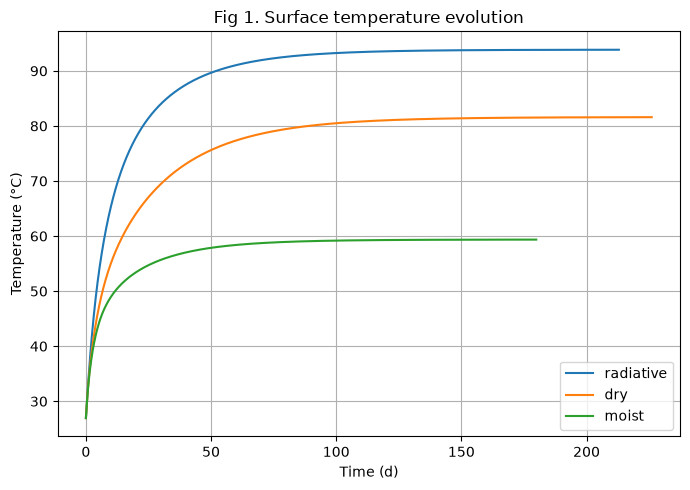

In [48]:
plt.figure(figsize=(7, 5))

for mode in ["radiative", "dry", "moist"]:
    history = history_save[mode]
    days = np.array(history["time"]) / 86400 # Convert time from seconds to days

    plt.plot(days, np.array(history["T_surf"]) - 273.15, label=mode) # Convert surface temperature from K to C

plt.title("Fig 1. Surface temperature evolution")
plt.xlabel("Time (d)")
plt.ylabel("Temperature (°C)")

plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

In the first figure, the surface temperature increases rapidly during the initial stages of the simulations. This shows that the atmosphere is adjusting to the  radiative forcing. As time passes, the temperature changes become smaller, and the curves eventually stabilize toward the equilibrium.

The three experiments reach different surface temperatures. From warmest to coldest:
- Radiative: 366.99 K
- Dry RCE: 354.74 K
- Moist RCE: 332.51 K 

This suggests that convective adjustment is important when determining the equilibrium temperature of the surface.

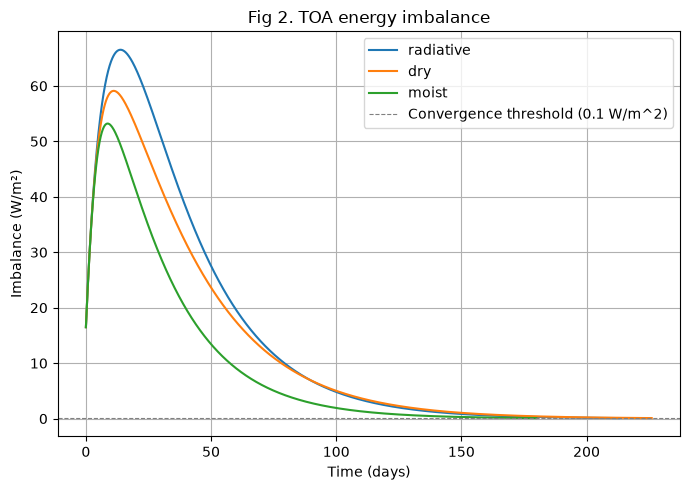

In [53]:
plt.figure(figsize=(7, 5))

for mode in ["radiative", "dry", "moist"]:

    history = history_save[mode]

    days = np.array(history["time"]) / 86400 # Convert time from seconds to days

    TOA_net = np.array(history["TOA_net"]) # Net energy imbalance at TOA (W/m2)

    plt.plot(days, TOA_net, label=mode)

plt.title("Fig 2. TOA energy imbalance")
plt.xlabel("Time (days)")
plt.ylabel("Imbalance (W/m²)")

# Convergence threshold used in the model
plt.axhline(0.1, color="grey", linestyle="--", linewidth=0.8, label="Convergence threshold (0.1 W/m^2)")

plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

The second figure shows the time evolution of the TOA energy imbalance (difference between incoming solar radiation and outgoing longwave radiation). Initially, the system is not in energy balance, but the imbalance progressively decreases as the model evolves. All three experiments eventually reach the prescribed convergence threshold of approximately 0.1 W/m², indicating that the outgoing LW radiation nearly balances the incoming SW solar radiation.

The figures help portray that the three simulations have approached equilibrium. The stabilization of surface temperature indicates that the system is reaching a steady state and the small TOA imbalance confirms that the column is approaching radiative energy balance. 

### 2. Skew-T with equilibrium profiles

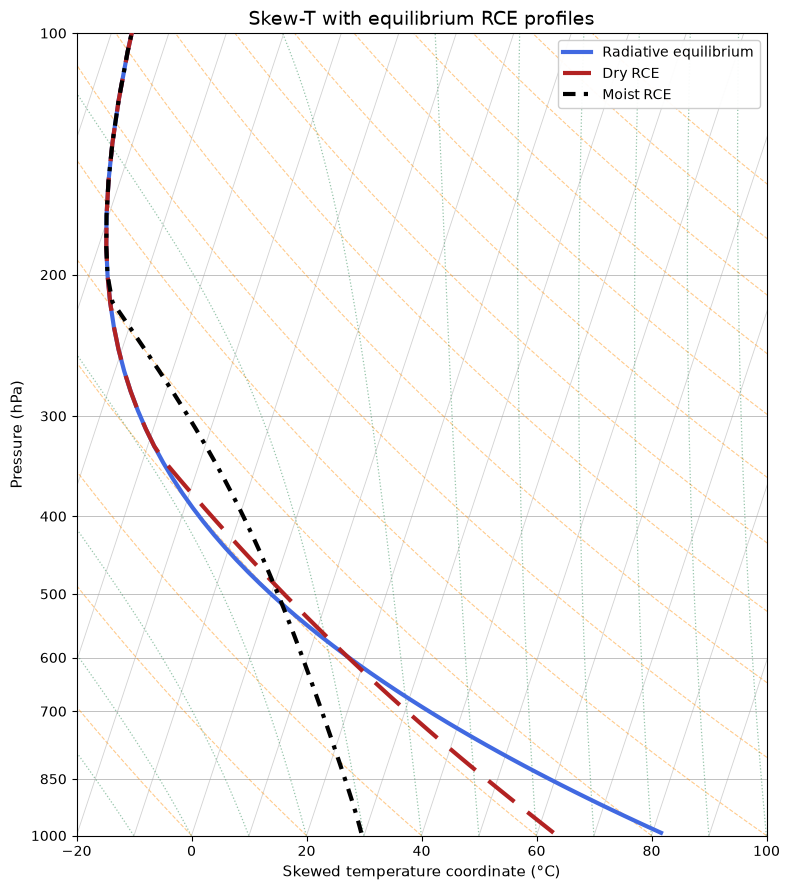

In [59]:
# ============================================================
# SKEW-T WITH FULL BACKGROUND AND FINAL RCE PROFILES
# ============================================================
# Uses the Skew-T functions from Lab 3 and overlays
# the final equilibrium temperature profiles from the three
# experiments: radiative, dry RCE, moist RCE.
#
# The background includes:
# - isotherms
# - dry adiabats
# - moist adiabats
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Constants for the Skew-T calculations
R_d = 287.0       # Dry air gas constant (J/kg/K)
R_v = 461.0       # Water vapor gas constant (J/kg/K)
c_pd = 1004.0     # Specific heat of dry air (J/kg/K)
L_v = 2.5e6       # Latent heat of vaporization (J/kg)
g = 9.81          # Gravitational acceleration (m/s²)

eps = R_d / R_v   # Ratio of gas constants

# ------------------------------------------------------------
# Basic Skew-T transform
# ------------------------------------------------------------
def skewT(temp, pres, skew=-20):
    """
    Skews temperature for a Skew-T plot.
    """
    return temp + skew * np.log(pres / 1000.0)


# ------------------------------------------------------------
# Dry adiabat
# ------------------------------------------------------------
def pot_T(T0, p, p0=1000):
    """
    Temperature evolution along a dry adiabat.
    """
    T0_K = T0 + 273.15
    T_K = T0_K * (p / p0)**(R_d / c_pd)
    return T_K - 273.15


# ------------------------------------------------------------
# Moist adiabat helper functions
# ------------------------------------------------------------
def e_s(T):
    """
    Saturation vapor pressure in hPa.
    T must be in Celsius.
    """
    T_K = T + 273.15
    return 6.112 * np.exp(17.67 * ((T_K - 273.15) / (T_K - 29.65)))


def r_s(es, p):
    """
    Saturation mixing ratio (dimensionless).
    es and p in hPa.
    """
    return eps * es / (p - es)


def rho(T, p):
    """
    Air density in kg/m^3.
    T in Celsius, p in hPa.
    """
    return (p * 100.0) / (R_d * (T + 273.15))


def alpha(rs, T):
    """
    Moist adiabat factor (dimensionless).
    rs is mixing ratio, T in Celsius.
    """
    T_K = T + 273.15
    return ((1 + (L_v * rs) / (R_d * T_K)) /
            (1 + (L_v**2 * rs) / (c_pd * R_v * T_K**2)))


def dT_dp(alpha_val, rho_val):
    """
    Temperature change with pressure in K/Pa.
    """
    return alpha_val / (c_pd * rho_val)


def moist_adiabat(T0, pres):
    """
    Builds one moist adiabat following the same step-by-step
    method used in Lab 3.
    """
    T_MA = []
    T_current = T0

    for p0 in pres:
        es0 = e_s(T_current)
        rs0 = r_s(es0, p0)
        rho0 = rho(T_current, p0)
        alpha0 = alpha(rs0, T_current)
        dT_dp0 = dT_dp(alpha0, rho0)

        # Pressure step is 1 hPa = 100 Pa
        Tf = T_current + dT_dp0 * (-100.0)

        T_MA = np.append(T_MA, Tf)
        T_current = Tf

    return T_MA


# Create the Skew-T background
def create_skewt_full(skew=-20):
    """
    Creates a Skew-T background with isotherms, dry adiabats,
    and moist adiabats spanning the full plot.
    """
    # Pressure array for background
    pres = np.arange(1000, 99, -1)

    # Standard pressure guides
    pres_guides = [1000, 850, 700, 600, 500, 400, 300, 200, 100]

    # Extended temperature ranges so background covers the whole figure.
    temp_IT = np.arange(-100, 161, 10)
    temp_DA = np.arange(-80, 301, 20)
    temp_MA = np.arange(-60, 121, 10)

    fig, ax = plt.subplots(figsize=(8, 9))

    # Pressure axis in log space
    ax.set_yscale("log")
    ax.set_ylim(1000, 100)

    ax.set_xlim(-20, 100) # Full profile coverage

    # Isotherms
    for T0 in temp_IT:
        T_sk = skewT(T0, pres, skew=skew)
        ax.plot(
            T_sk, pres,
            color="0.75",
            linewidth=0.6,
            alpha=0.7,
            zorder=1
        )

    # Isobars
    for p in pres_guides:
        ax.axhline(
            p,
            color="0.65",
            linewidth=0.7,
            alpha=0.7,
            zorder=1
        )

    # Dry adiabats
    for T0 in temp_DA:
        T_DA = pot_T(T0, pres)
        ax.plot(
            skewT(T_DA, pres, skew=skew),
            pres,
            color="darkorange",
            linestyle="--",
            linewidth=0.8,
            alpha=0.45,
            zorder=2
        )

    # Moist adiabats
    for T0 in temp_MA:
        T_MA = moist_adiabat(T0, pres)
        ax.plot(
            skewT(T_MA, pres, skew=skew),
            pres,
            color="seagreen",
            linestyle=":",
            linewidth=0.9,
            alpha=0.50,
            zorder=2
        )

    # Axis formatting
    ax.set_yticks(pres_guides)
    ax.set_yticklabels([str(p) for p in pres_guides])
    ax.minorticks_off()

    ax.set_xlabel("Skewed temperature coordinate (°C)", fontsize=11)
    ax.set_ylabel("Pressure (hPa)", fontsize=11)
    ax.set_title("Skew-T with equilibrium RCE profiles", fontsize=14)

    return fig, ax


# Plot final equilibrium profiles on top of the Skew-T
skew = -20
fig, ax = create_skewt_full(skew=skew)

# Pressure from model levels (convert Pa to hPa)
p_model = grid["p_mid"] / 100.0

# Final equilibrium temperature profiles (K -> C)
T_rad = np.array(history_save["radiative"]["T"][-1]) - 273.15
T_dry = np.array(history_save["dry"]["T"][-1]) - 273.15
T_moist = np.array(history_save["moist"]["T"][-1]) - 273.15

# Skew the three temperature profiles
T_rad_sk = skewT(T_rad, p_model, skew=skew)
T_dry_sk = skewT(T_dry, p_model, skew=skew)
T_moist_sk = skewT(T_moist, p_model, skew=skew)

# Final profiles
# Radiative
ax.plot(
    T_rad_sk, p_model,
    color="royalblue",
    linewidth=3.0,
    linestyle="-",
    label="Radiative equilibrium",
    zorder=5
)

# Dry RCE
ax.plot(
    T_dry_sk, p_model,
    color="firebrick",
    linewidth=3.0,
    linestyle=(0, (8, 4)),
    label="Dry RCE",
    zorder=6
)

# Moist RCE
ax.plot(
    T_moist_sk, p_model,
    color="black",
    linewidth=3.0,
    linestyle=(0, (3, 2, 1, 2)),
    label="Moist RCE",
    zorder=7
)

# Legend
ax.legend(
    loc="upper right",
    frameon=True,
    facecolor="white",
    framealpha=0.95,
    fontsize=10
)

plt.tight_layout()
plt.show()